In [1]:
import pandas as pd
from pathlib import Path

In [2]:
path = Path("./datasets/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv")
df = pd.read_csv(path, parse_dates=["service_date"])
df.columns = ["date","day_type", "bus", "rail", "total"] # rename columns
df = df.sort_values("date").set_index("date")
df.drop(columns=["total"], inplace=True)
df = df.drop_duplicates()
df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


In [3]:
import matplotlib.pyplot as plt

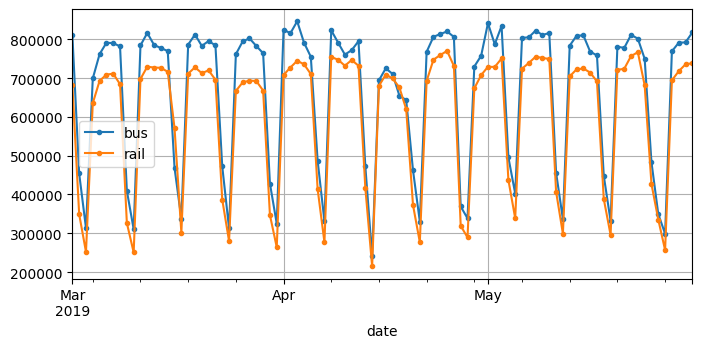

In [5]:
df["2019-03":"2019-05"].plot(grid=True,marker=".",figsize = (8, 3.5))
plt.show()

### Navie forecasting

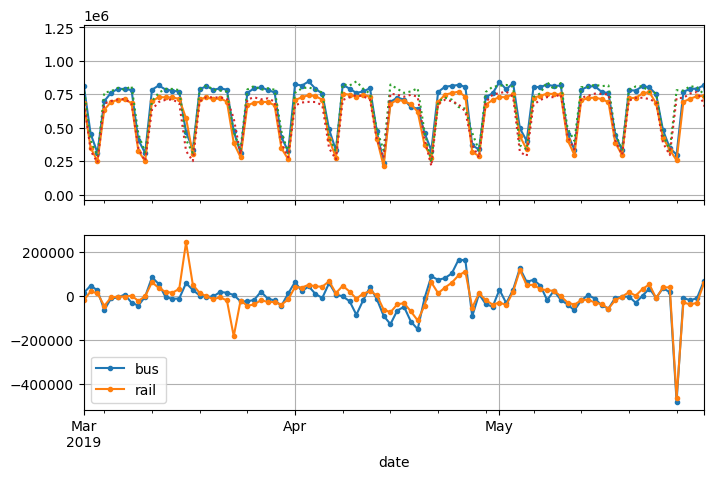

In [24]:
diff_7 = df[["bus","rail"]].diff(7)["2019-03":"2019-05"]

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
df.plot(ax=axs[0], legend=False, marker=".") # original 
df.shift(7).plot(ax=axs[0], legend=False, linestyle=":", grid=True) # lagged
diff_7.plot(ax=axs[1],grid=True, marker=".")
plt.show()

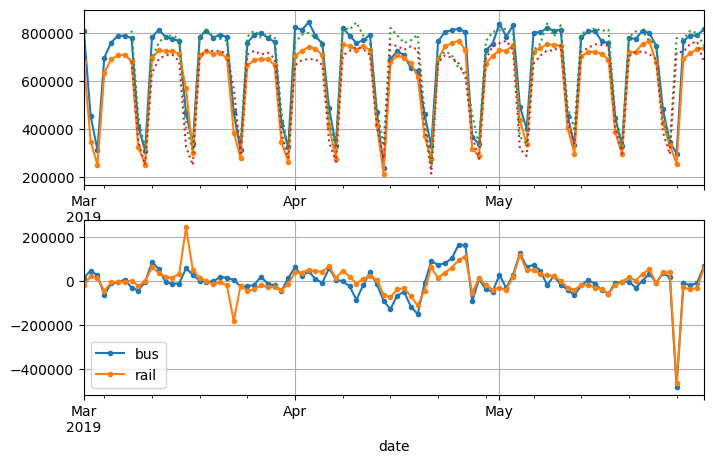

In [18]:
diff_7 = df[["bus", "rail"]].diff(7)["2019-03":"2019-05"]

fig, axs = plt.subplots(2, 1, figsize=(8, 5))
df["2019-03":"2019-05"].plot(ax=axs[0], legend=False, marker=".")  # original time series
df["2019-03":"2019-05"].shift(7).plot(ax=axs[0], grid=True, legend=False, linestyle=":")  # lagged
diff_7.plot(ax=axs[1], grid=True, marker=".")  # 7-day difference time series
axs[0].set_ylim([170_000, 900_000])  # extra code – beautifies the plot
plt.show()

In [27]:
# Mean absolut error (MAE)
diff_7.abs().mean()

bus     43915.608696
rail    42143.271739
dtype: float64

In [29]:
# Mean absolute percentile error (MAPE)
target = df[["bus", "rail"]]["2019-03":"2019-05"]
(diff_7/target).abs().mean()

bus     0.082938
rail    0.089948
dtype: float64